# PCA: frecuencia de observación y duración de memoria

Se comparan dos controles con candidatos fijos, PCA + media al 95%, QR directo y 128 puntos activos completados con Sobol. Se mantiene la pérdida histórica datos+PDE+IC, red, semillas, Adam, 100 pasos uniformes y 10000 de continuación, con reconstrucción cada 100 pasos.

**Frecuencia:** observar cada 5, 10 o 20 pasos sobre los últimos 100 pasos. Cambia la densidad de observaciones, manteniendo el horizonte. **Memoria:** conservar los últimos 100, 200 o 400 pasos observando cada 5. Cambia el horizonte, manteniendo la cadencia. Los cambios del rango efectivo son parte de la respuesta del método adaptativo. No se conserva artificialmente la dimensión de la base.

La primera selección usa la misma historia común del warmup. Después las historias contienen únicamente snapshots de continuación; las ventanas largas se llenan gradualmente y están completas desde los pasos totales 300 y 500. Esto evita modificar el estado inicial para introducir una historia larga. Durante ese arranque no se puede atribuir la diferencia exclusivamente a un horizonte completo. El caso memoria 100/cadencia 5 se reutiliza del notebook 19.

En todos los casos cada fila conserva sus coordenadas, los snapshots tienen signo y se evalúan después de Adam. Una ventana de 100 con cadencia 5 contiene 20 observaciones desde paso t−95 hasta t; el horizonte nominal se define por el intervalo (t−100,t]. El rango total incluye la media y puede superar 32 en las ventanas largas; QR directo selecciona k puntos y completa con 128−k Sobol. No hay ampliación log-det ni poda. No se afirma ahorro temporal; observar más frecuentemente añade costo.

| Cadencia | Memoria | RMSE prueba ± DE | Residuo RMS | Rango medio |
|---:|---:|---:|---:|---:|
| 5 | 100 | 0.07144 ± 0.00977 | 0.16801 | 5.30 |
| 10 | 100 | 0.07626 ± 0.02428 | 0.17188 | 4.19 |
| 20 | 100 | 0.06970 ± 0.01216 | 0.18816 | 3.18 |
| 5 | 200 | 0.08881 ± 0.03187 | 0.18880 | 6.25 |
| 5 | 400 | 0.07457 ± 0.02530 | 0.15445 | 8.28 |


f10_m100 frente a cadencia 5/memoria 100: diferencia media RMSE +0.00482, mejora en 5/10 semillas.

f20_m100 frente a cadencia 5/memoria 100: diferencia media RMSE -0.00173, mejora en 6/10 semillas.

f5_m200 frente a cadencia 5/memoria 100: diferencia media RMSE +0.01737, mejora en 4/10 semillas.

f5_m400 frente a cadencia 5/memoria 100: diferencia media RMSE +0.00313, mejora en 7/10 semillas.

**Comparación**

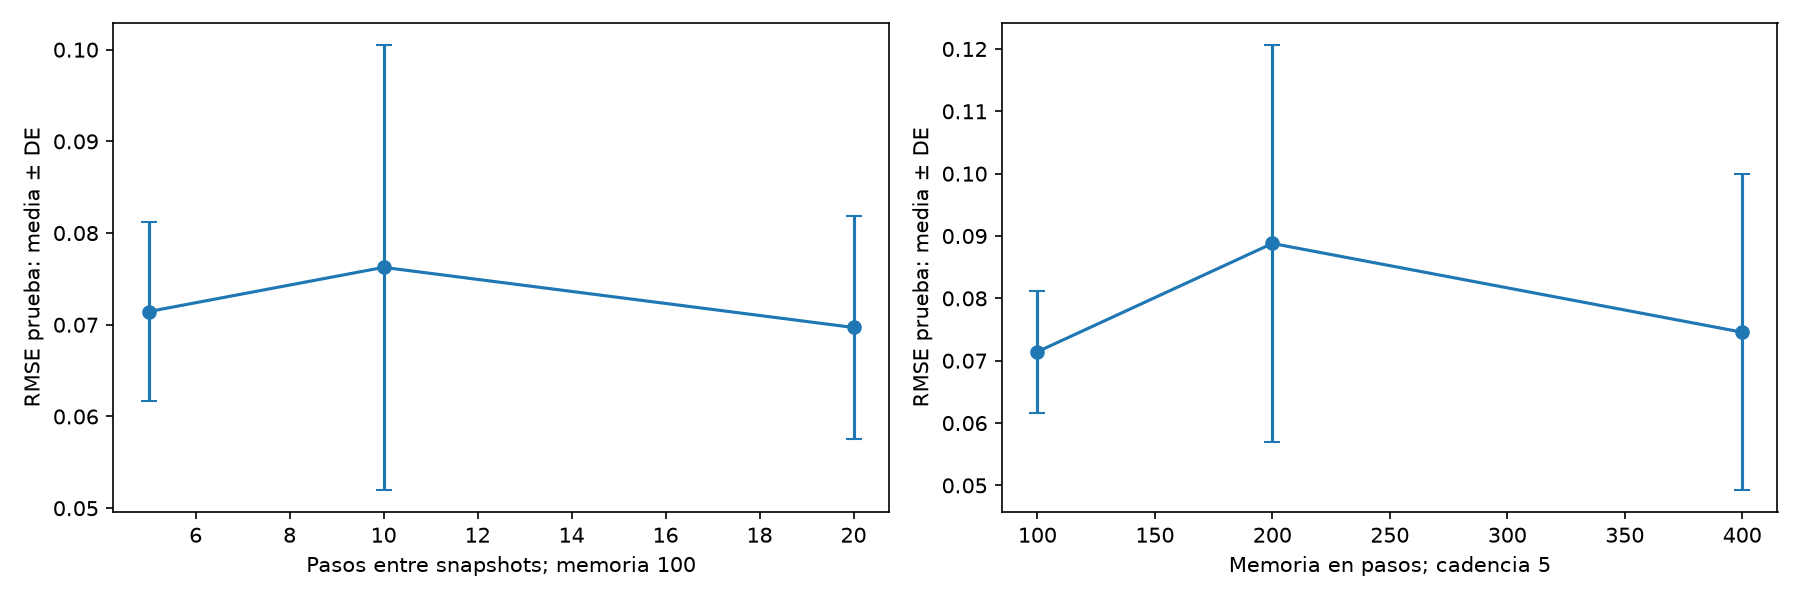

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/memory_cadence/cadence_memory_10_seeds_10k_v1/comparison.png'), format='png', embed=True))


Se evalúan los modelos terminales en prueba reservada; no se eligen configuraciones por prueba. Las diferencias son exploratorias y deben confirmarse con nuevas semillas. Los monitores de validación, residuo, IC y BC están en las trazas por semilla. La desviación representa dispersión entre semillas.

Reproducir: `python scripts/run_collocation_memory.py`. memory_history.csv conserva tiempos reales y estado de llenado de cada ventana, memory_audit.npz sus matrices con signo y coordenadas. manifest.json identifica las referencias reutilizadas. Las figuras están incrustadas como PNG.